# Autoregressive Text Generation with Simple RNN, Bidirectional RNN, LSTM and GRU

**Course:** Foundations of Generative AI (ICT4403) – Assignment 2
**Name:** Anuran Baruah
**Registration No.:** 220911544

This notebook builds a word-level next-word prediction system on *The Adventures of Sherlock Holmes*
(Arthur Conan Doyle, Project Gutenberg) and compares four recurrent architectures trained under the
same conditions. Text is then generated autoregressively from fixed seed sequences at several
sampling temperatures.

**Contents**
1. Setup
2. Dataset description
3. Pre-processing and input–target sequence construction
4. Model definitions
5. Training
6. Quantitative evaluation (loss, perplexity, accuracy, training time)
7. Text generation and temperature analysis
8. Discussion and conclusion

## 1. Setup

In [1]:
import os, re, time, random, math
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

DATA_PATH = "data/sherlock_holmes.txt"
RESULTS_DIR = "results"
PLOTS_DIR = os.path.join(RESULTS_DIR, "plots")
os.makedirs(PLOTS_DIR, exist_ok=True)

PyTorch: 2.14.1+cu126 | device: cuda
GPU: NVIDIA GeForce GTX 1650


## 2. Dataset description

* **Name:** *The Adventures of Sherlock Holmes* by Arthur Conan Doyle (1892)
* **Source:** Project Gutenberg, eBook #1661 – https://www.gutenberg.org/ebooks/1661
  (plain text: https://www.gutenberg.org/cache/epub/1661/pg1661.txt)
* **Licence:** Public domain in the USA
* **Content:** 12 short detective stories narrated by Dr. Watson. The language is late-Victorian
  English prose with long sentences, a lot of dialogue and a recurring set of characters
  (Holmes, Watson, Lestrade) and themes (crime, clues, deduction).

The file is downloaded automatically if it is not already present. The Project Gutenberg
licence header and footer are removed so that only the book text is used.

In [2]:
if not os.path.exists(DATA_PATH):
    import urllib.request
    os.makedirs("data", exist_ok=True)
    urllib.request.urlretrieve("https://www.gutenberg.org/cache/epub/1661/pg1661.txt", DATA_PATH)

with open(DATA_PATH, encoding="utf-8") as f:
    raw = f.read()

start = raw.find("*** START OF THE PROJECT GUTENBERG EBOOK")
end = raw.find("*** END OF THE PROJECT GUTENBERG EBOOK")
book = raw[raw.find("\n", start) + 1:end]
# skip the table of contents, the stories start at "I. A SCANDAL IN BOHEMIA"
book = book[book.find("I. A SCANDAL IN BOHEMIA"):]

words_raw = book.split()
sentences = re.split(r"[.!?]+\s", book)
stories = re.findall(r"^[IVX]+\. [A-Z][A-Z ,’'-]+$", book, flags=re.M)

print(f"Characters          : {len(book):,}")
print(f"Lines               : {book.count(chr(10)):,}")
print(f"Words (whitespace)  : {len(words_raw):,}")
print(f"Approx. sentences   : {len(sentences):,}")
print(f"Avg words/sentence  : {len(words_raw) / len(sentences):.1f}")
print(f"Stories             : {len(stories)}")
print()
print(book[:600])

Characters          : 561,660
Lines               : 11,905
Words (whitespace)  : 104,423
Approx. sentences   : 5,138
Avg words/sentence  : 20.3
Stories             : 12

I. A SCANDAL IN BOHEMIA


I.

To Sherlock Holmes she is always _the_ woman. I have seldom heard him
mention her under any other name. In his eyes she eclipses and
predominates the whole of her sex. It was not that he felt any emotion
akin to love for Irene Adler. All emotions, and that one particularly,
were abhorrent to his cold, precise but admirably balanced mind. He
was, I take it, the most perfect reasoning and observing machine that
the world has seen, but as a lover he would have placed himself in a
false position. He never spoke of the softer passions, save with a gibe
and a sneer. The


## 3. Pre-processing and input–target sequence construction

Steps:
1. Normalise typographic characters (curly quotes/apostrophes, em-dashes, `_italic_` markers).
2. Lower-case the text.
3. Tokenise into words (keeping internal apostrophes, e.g. `don't`, `holmes's`) and the punctuation
   marks `. , ? ! ; :` as separate tokens, so the models also learn sentence structure.
   Quotation marks are dropped.
4. Build a vocabulary of words that appear at least twice. Rare words are mapped to `<unk>`.
5. Split the token stream **chronologically** into 80 % train, 10 % validation and 10 % test,
   so no overlapping windows leak between splits.
6. Slide a window of `SEQ_LEN = 15` tokens over each split: the 15 tokens are the input and the
   16th token is the target (many-to-one next-word prediction).

In [3]:
def normalise(text):
    text = text.replace("’", "'").replace("‘", "'").replace("“", '"').replace("”", '"')
    text = text.replace("—", " ").replace("_", " ").replace("-", " ")
    return text.lower()

def tokenize(text):
    return re.findall(r"[a-z0-9]+(?:'[a-z]+)*|[.,!?;:]", normalise(text))

tokens = tokenize(book)
counts = Counter(tokens)
print(f"Total tokens  : {len(tokens):,}")
print(f"Unique tokens : {len(counts):,}")
print(f"Tokens seen only once: {sum(1 for c in counts.values() if c == 1):,}")
print("Most common:", counts.most_common(25))

Total tokens  : 120,534
Unique tokens : 8,017
Tokens seen only once: 3,571
Most common: [(',', 7659), ('.', 6196), ('the', 5612), ('and', 3018), ('i', 3002), ('to', 2744), ('of', 2647), ('a', 2640), ('in', 1765), ('that', 1744), ('it', 1701), ('you', 1481), ('he', 1467), ('was', 1410), ('his', 1159), ('is', 1124), ('my', 1007), ('have', 924), ('as', 852), ('had', 831), ('with', 829), ('which', 771), ('at', 769), ('?', 738), ('for', 726)]


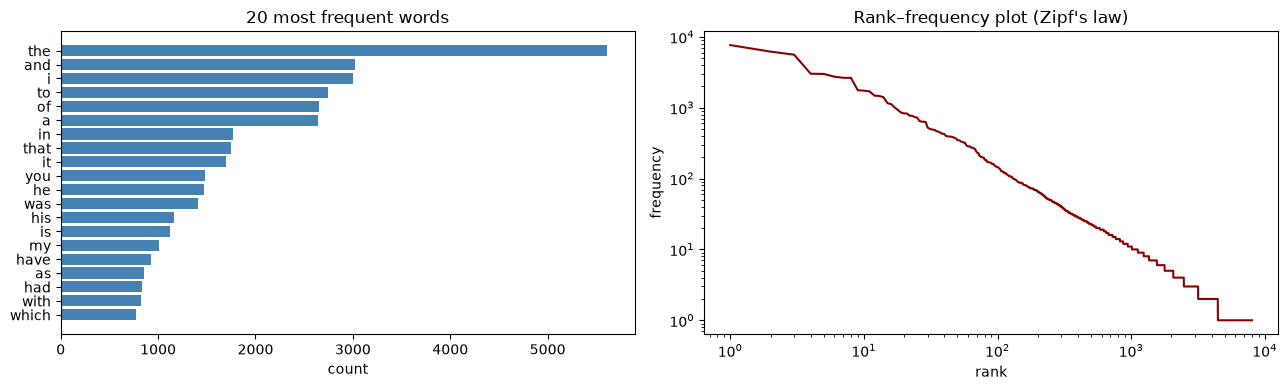

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
top = [(w, c) for w, c in counts.most_common(60) if w not in ".,!?;:"][:20]
axes[0].barh([w for w, _ in top][::-1], [c for _, c in top][::-1], color="steelblue")
axes[0].set_title("20 most frequent words")
axes[0].set_xlabel("count")

freqs = np.array(sorted(counts.values(), reverse=True))
axes[1].loglog(np.arange(1, len(freqs) + 1), freqs, color="darkred")
axes[1].set_title("Rank–frequency plot (Zipf's law)")
axes[1].set_xlabel("rank")
axes[1].set_ylabel("frequency")
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, "dataset_word_frequency.png"), dpi=120)
plt.show()

In [5]:
MIN_FREQ = 2
SEQ_LEN = 15

itos = ["<pad>", "<unk>"] + sorted(w for w, c in counts.items() if c >= MIN_FREQ)
stoi = {w: i for i, w in enumerate(itos)}
UNK = stoi["<unk>"]
VOCAB_SIZE = len(itos)

ids = np.array([stoi.get(t, UNK) for t in tokens], dtype=np.int64)
print(f"Vocabulary size: {VOCAB_SIZE:,}")
print(f"<unk> rate: {(ids == UNK).mean() * 100:.2f}% of tokens")

n = len(ids)
train_ids = ids[: int(0.8 * n)]
val_ids = ids[int(0.8 * n): int(0.9 * n)]
test_ids = ids[int(0.9 * n):]

def make_sequences(arr, seq_len=SEQ_LEN):
    windows = np.lib.stride_tricks.sliding_window_view(arr, seq_len + 1)
    return torch.from_numpy(windows[:, :-1].copy()), torch.from_numpy(windows[:, -1].copy())

X_train, y_train = make_sequences(train_ids)
X_val, y_val = make_sequences(val_ids)
X_test, y_test = make_sequences(test_ids)
print(f"Train sequences: {len(X_train):,} | Val: {len(X_val):,} | Test: {len(X_test):,}")

print("\nExample input–target pairs:")
for i in range(0, 4):
    print(" ".join(itos[t] for t in X_train[i].tolist()), " -->", itos[y_train[i]])

Vocabulary size: 4,448
<unk> rate: 2.96% of tokens
Train sequences: 96,412 | Val: 12,038 | Test: 12,039

Example input–target pairs:
i . a scandal in bohemia i . to sherlock holmes she is always the  --> woman
. a scandal in bohemia i . to sherlock holmes she is always the woman  --> .
a scandal in bohemia i . to sherlock holmes she is always the woman .  --> i
scandal in bohemia i . to sherlock holmes she is always the woman . i  --> have


## 4. Model definitions

All four models share the same structure so that the comparison is fair:

`Embedding (128)` → `2-layer recurrent block (256 hidden units, dropout 0.3)` → `Dropout` → `Linear → vocabulary logits`

Only the recurrent block changes:

| Model | Recurrent block |
|---|---|
| Simple RNN | `nn.RNN` (tanh) – plain recurrence, suffers from vanishing gradients on long contexts |
| Bidirectional RNN | `nn.RNN(bidirectional=True)` – reads the 15-token **input window** forwards and backwards; the final forward and backward states are concatenated. It never sees the target word, so it is still a valid next-word predictor. |
| LSTM | `nn.LSTM` – input, forget and output gates plus a cell state for long-range memory |
| GRU | `nn.GRU` – update and reset gates, fewer parameters than LSTM |

The prediction is made from the final hidden state of the last layer (many-to-one).

In [6]:
class NextWordModel(nn.Module):
    def __init__(self, cell, vocab_size, emb_dim=128, hidden=256, layers=2,
                 bidirectional=False, dropout=0.3):
        super().__init__()
        rnn_cls = {"rnn": nn.RNN, "lstm": nn.LSTM, "gru": nn.GRU}[cell]
        self.bidirectional = bidirectional
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        self.rnn = rnn_cls(emb_dim, hidden, num_layers=layers, batch_first=True,
                           dropout=dropout, bidirectional=bidirectional)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden * (2 if bidirectional else 1), vocab_size)

    def forward(self, x):
        _, h = self.rnn(self.embedding(x))
        if isinstance(h, tuple):          # LSTM returns (h_n, c_n)
            h = h[0]
        if self.bidirectional:            # last layer: forward state + backward state
            last = torch.cat([h[-2], h[-1]], dim=1)
        else:
            last = h[-1]
        return self.fc(self.dropout(last))


MODEL_SPECS = {
    "SimpleRNN": dict(cell="rnn"),
    "BiRNN": dict(cell="rnn", bidirectional=True),
    "LSTM": dict(cell="lstm"),
    "GRU": dict(cell="gru"),
}

for name, spec in MODEL_SPECS.items():
    m = NextWordModel(vocab_size=VOCAB_SIZE, **spec)
    print(f"{name:10s} parameters: {sum(p.numel() for p in m.parameters()):,}")

SimpleRNN  parameters: 1,942,880
BiRNN      parameters: 3,443,040
LSTM       parameters: 2,634,080
GRU        parameters: 2,403,680


## 5. Training

Identical conditions for every model:

* Loss: cross-entropy over the vocabulary
* Optimiser: Adam, learning rate 0.001, batch size 128
* Gradient clipping at norm 5 (important for the simple RNNs)
* Up to 25 epochs with **early stopping** (patience 3) on validation loss; the best weights are restored
* Same random seed and the same data order for each model

In [7]:
BATCH_SIZE = 128
EPOCHS = 25
LR = 1e-3
PATIENCE = 3
CLIP = 5.0

train_loader_gen = torch.Generator().manual_seed(SEED)

def make_loader(X, y, shuffle):
    return DataLoader(TensorDataset(X, y), batch_size=BATCH_SIZE, shuffle=shuffle,
                      generator=train_loader_gen if shuffle else None)

val_loader = make_loader(X_val, y_val, False)
test_loader = make_loader(X_test, y_test, False)
criterion = nn.CrossEntropyLoss()


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss, correct, correct5, count = 0.0, 0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)
        total_loss += criterion(logits, yb).item() * len(yb)
        top5 = logits.topk(5, dim=1).indices
        correct += (top5[:, 0] == yb).sum().item()
        correct5 += (top5 == yb[:, None]).any(dim=1).sum().item()
        count += len(yb)
    loss = total_loss / count
    return {"loss": loss, "perplexity": math.exp(loss), "acc": correct / count, "top5_acc": correct5 / count}


def train_model(name, spec):
    torch.manual_seed(SEED)
    train_loader_gen.manual_seed(SEED)
    model = NextWordModel(vocab_size=VOCAB_SIZE, **spec).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    train_loader = make_loader(X_train, y_train, True)

    history, best_loss, best_state, bad_epochs = [], float("inf"), None, 0
    if device.type == "cuda":
        torch.cuda.synchronize()
    t0 = time.time()
    for epoch in range(1, EPOCHS + 1):
        model.train()
        ep_start, run_loss, run_correct, seen = time.time(), 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), CLIP)
            optimizer.step()
            run_loss += loss.item() * len(yb)
            run_correct += (logits.argmax(1) == yb).sum().item()
            seen += len(yb)
        val = evaluate(model, val_loader)
        history.append({"model": name, "epoch": epoch,
                        "train_loss": run_loss / seen, "train_acc": run_correct / seen,
                        "val_loss": val["loss"], "val_acc": val["acc"],
                        "val_perplexity": val["perplexity"], "epoch_time_s": time.time() - ep_start})
        print(f"{name:10s} epoch {epoch:2d} | train loss {run_loss/seen:.3f} acc {run_correct/seen:.3f} "
              f"| val loss {val['loss']:.3f} ppl {val['perplexity']:.1f} acc {val['acc']:.3f} "
              f"| {time.time() - ep_start:.1f}s")
        if val["loss"] < best_loss:
            best_loss, bad_epochs = val["loss"], 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad_epochs += 1
            if bad_epochs >= PATIENCE:
                print(f"{name}: early stopping after epoch {epoch}")
                break
    if device.type == "cuda":
        torch.cuda.synchronize()
    train_time = time.time() - t0
    model.load_state_dict(best_state)
    return model, history, train_time

In [8]:
models, histories, train_times = {}, [], {}
for name, spec in MODEL_SPECS.items():
    model, hist, t = train_model(name, spec)
    models[name], train_times[name] = model, t
    histories.extend(hist)
    print(f"--> {name} finished in {t:.1f}s\n")

history_df = pd.DataFrame(histories)
history_df.to_csv(os.path.join(RESULTS_DIR, "training_history.csv"), index=False)

SimpleRNN  epoch  1 | train loss 5.596 acc 0.120 | val loss 5.156 ppl 173.5 acc 0.139 | 7.0s


SimpleRNN  epoch  2 | train loss 4.973 acc 0.153 | val loss 5.031 ppl 153.1 acc 0.153 | 6.6s


SimpleRNN  epoch  3 | train loss 4.696 acc 0.166 | val loss 4.971 ppl 144.2 acc 0.165 | 6.6s


SimpleRNN  epoch  4 | train loss 4.486 acc 0.178 | val loss 4.962 ppl 142.9 acc 0.168 | 6.7s


SimpleRNN  epoch  5 | train loss 4.327 acc 0.183 | val loss 4.964 ppl 143.1 acc 0.173 | 6.7s


...

GRU        epoch  3 | train loss 4.587 acc 0.185 | val loss 4.837 ppl 126.1 acc 0.175 | 7.7s


GRU        epoch  4 | train loss 4.317 acc 0.200 | val loss 4.821 ppl 124.1 acc 0.184 | 7.7s


GRU        epoch  5 | train loss 4.071 acc 0.217 | val loss 4.843 ppl 126.8 acc 0.186 | 7.7s


GRU        epoch  6 | train loss 3.849 acc 0.232 | val loss 4.862 ppl 129.3 acc 0.182 | 7.7s


GRU        epoch  7 | train loss 3.639 acc 0.251 | val loss 4.919 ppl 136.9 acc 0.184 | 7.7s
GRU: early stopping after epoch 7
--> GRU finished in 53.8s



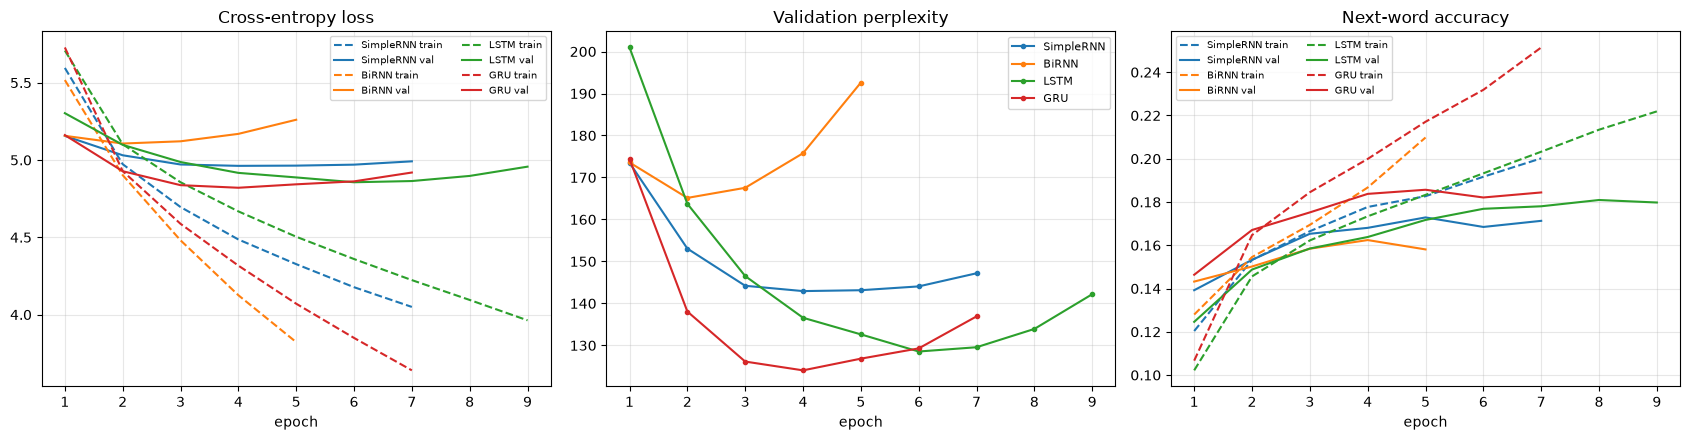

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
colors = {"SimpleRNN": "tab:blue", "BiRNN": "tab:orange", "LSTM": "tab:green", "GRU": "tab:red"}
for name, g in history_df.groupby("model", sort=False):
    axes[0].plot(g.epoch, g.train_loss, "--", color=colors[name], label=f"{name} train")
    axes[0].plot(g.epoch, g.val_loss, "-", color=colors[name], label=f"{name} val")
    axes[1].plot(g.epoch, g.val_perplexity, "-o", ms=3, color=colors[name], label=name)
    axes[2].plot(g.epoch, g.train_acc, "--", color=colors[name], label=f"{name} train")
    axes[2].plot(g.epoch, g.val_acc, "-", color=colors[name], label=f"{name} val")
axes[0].set_title("Cross-entropy loss")
axes[1].set_title("Validation perplexity")
axes[2].set_title("Next-word accuracy")
for ax in axes:
    ax.set_xlabel("epoch")
    ax.grid(alpha=0.3)
axes[0].legend(fontsize=7, ncol=2)
axes[1].legend(fontsize=8)
axes[2].legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, "training_curves.png"), dpi=120)
plt.show()

## 6. Quantitative evaluation on the held-out test split

* **Loss** – mean cross-entropy on the test sequences
* **Perplexity** – `exp(loss)`, the effective number of words the model is choosing between (lower is better)
* **Top-1 / Top-5 accuracy** – how often the true next word is the top prediction / among the top five
* **Training time** – wall-clock time until early stopping, and time per epoch

In [10]:
rows = []
for name, model in models.items():
    test = evaluate(model, test_loader)
    h = history_df[history_df.model == name]
    best = h.loc[h.val_loss.idxmin()]
    rows.append({
        "model": name,
        "parameters": sum(p.numel() for p in model.parameters()),
        "epochs_run": len(h),
        "best_epoch": int(best.epoch),
        "train_loss": round(best.train_loss, 4),
        "val_loss": round(best.val_loss, 4),
        "test_loss": round(test["loss"], 4),
        "test_perplexity": round(test["perplexity"], 2),
        "test_top1_acc": round(test["acc"], 4),
        "test_top5_acc": round(test["top5_acc"], 4),
        "train_time_s": round(train_times[name], 1),
        "time_per_epoch_s": round(h.epoch_time_s.mean(), 2),
    })
results_df = pd.DataFrame(rows)
results_df.to_csv(os.path.join(RESULTS_DIR, "model_comparison.csv"), index=False)
results_df

,model,parameters,epochs_run,best_epoch,train_loss,val_loss,test_loss,test_perplexity,test_top1_acc,test_top5_acc,train_time_s,time_per_epoch_s
0,SimpleRNN,1942880,7,4,4.4861,4.9624,4.9934,147.44,0.1723,0.3940,47.1,6.73
1,BiRNN,3443040,5,2,4.9023,5.1067,5.1210,167.50,0.1594,0.3725,58.2,11.63
2,LSTM,2634080,9,6,4.3596,4.8563,4.8689,130.18,0.1853,0.4046,83.0,9.22
3,GRU,2403680,7,4,4.3169,4.8207,4.8515,127.93,0.1889,0.4068,53.8,7.68


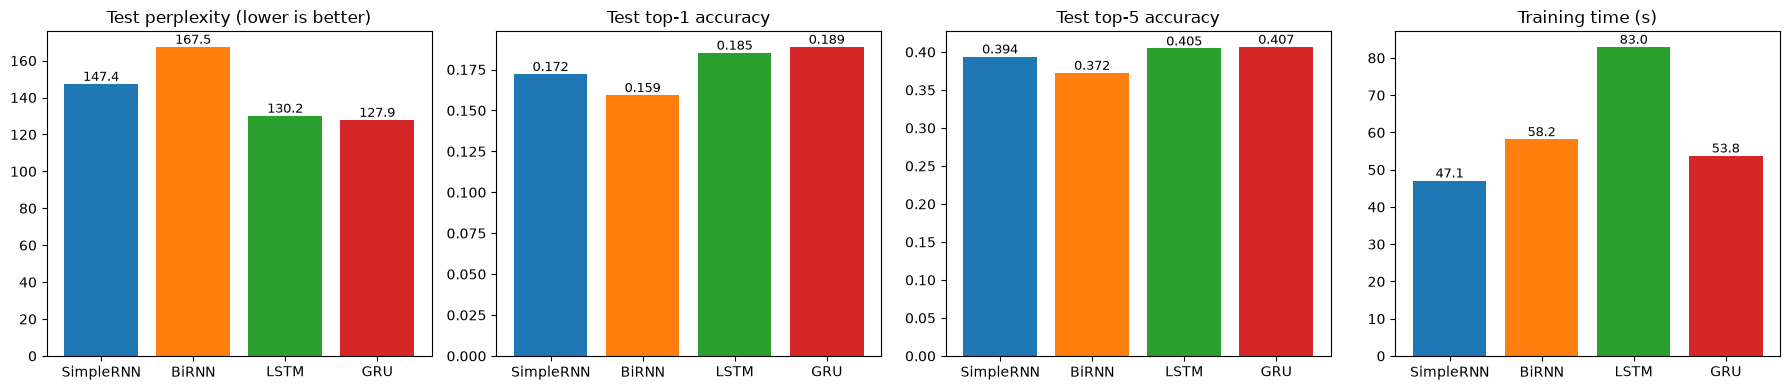

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
names = results_df.model.tolist()
bar_colors = [colors[n] for n in names]
for ax, col, title in zip(axes,
                          ["test_perplexity", "test_top1_acc", "test_top5_acc", "train_time_s"],
                          ["Test perplexity (lower is better)", "Test top-1 accuracy",
                           "Test top-5 accuracy", "Training time (s)"]):
    ax.bar(names, results_df[col], color=bar_colors)
    ax.set_title(title)
    for i, v in enumerate(results_df[col]):
        ax.text(i, v, f"{v:.3f}" if v < 1 else f"{v:.1f}", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, "test_metrics.png"), dpi=120)
plt.show()

### Discussion of the quantitative results

* **GRU** gives the lowest test loss (4.85), the lowest perplexity (≈128) and the highest top-1 (18.9 %)
  and top-5 (40.7 %) accuracy. **LSTM** is a close second (perplexity ≈130) but needs two more epochs
  and a slower step, so its total training time is roughly 1.5× that of the GRU.
* **Simple RNN** is noticeably worse (perplexity ≈147) but is the fastest model per epoch. With a
  15-token window the vanishing-gradient problem is less severe than it would be on long sequences,
  which is why the gap to the gated models is moderate rather than large.
* **Bidirectional RNN** performs worst (perplexity ≈168) despite having the most parameters. In
  next-word prediction the backward direction can only re-read the same past context, so it adds no
  new information; the extra capacity mostly helps the model memorise the training text, and it starts
  overfitting after just 2 epochs. It is also the slowest per epoch because it runs two recurrences.
* All four models overfit quickly (training loss keeps falling while validation loss rises after
  epoch 2–6). The corpus is small (~96k training tokens), so early stopping is essential.
* A perplexity of ~130 means that, on unseen text, the GRU is on average about as uncertain as if it were
  choosing uniformly between 130 words, compared with a vocabulary of more than 4,400 words.

## 7. Text generation and temperature analysis

Generation is autoregressive: the model predicts a distribution over the next word, a word is
sampled, appended to the context, and the last 15 tokens are fed back in. Temperature `T` rescales
the logits before the softmax, `p_i ∝ exp(z_i / T)`:

* `T < 1` sharpens the distribution (safer, more repetitive),
* `T = 1` samples from the model's own distribution,
* `T > 1` flattens it (more diverse, more random).

Every model is given **the same five seed sequences** and four temperatures (0.2, 0.5, 1.0, 1.5).
`<unk>` is never sampled. Each (model, seed, temperature) combination is sampled 3 times with fixed
random seeds (different for every model) and 50 new tokens are generated.

Automatic measures of the generated text (averaged over all 15 samples per cell):

| Measure | What it captures |
|---|---|
| **Distinct-1 / Distinct-2** | share of unique words / unique bigrams in the generated text → *diversity* |
| **Repetition (rep-3)** | share of word trigrams that are repeats of an earlier trigram → *repetition* |
| **Corpus bigram hit rate** | share of generated bigrams that also occur in the training text → a proxy for local *coherence / fluency* |
| **Seed-word recall** | share of the seed's content words (non-stopwords) that re-appear in the continuation → a rough proxy for *contextual consistency* |

In [12]:
SEEDS = [
    "i had called upon my friend sherlock holmes one day in the autumn of last year and found him",
    "it was a cold and stormy night , and the rain beat against the windows as we sat by the fire",
    "holmes took the letter from her hand and read it carefully . then he turned to me and said",
    "the young lady was dressed in black , and her face was pale with fear as she told us",
    "we took the train down to the little village , where the inspector was waiting for us at the",
]
TEMPERATURES = [0.2, 0.5, 1.0, 1.5]
GEN_LEN = 50
SAMPLES_PER_SEED = 3

STOPWORDS = set("""a an the and or but of to in on at for with by from as is was were be been
he she it i we you they him her his its my our your their me us them that this which who what
had have has do did not no so then there here when where very upon into said , . ? ! ; :""".split())

train_bigrams = set(zip(train_ids[:-1].tolist(), train_ids[1:].tolist()))


def detokenize(toks):
    text = " ".join(toks)
    return re.sub(r" ([.,!?;:])", r"\1", text)


@torch.no_grad()
def generate(model, seed_text, temperature, n_words=GEN_LEN, rng_seed=0):
    model.eval()
    gen = torch.Generator(device=device).manual_seed(rng_seed)
    context = [stoi.get(t, UNK) for t in tokenize(seed_text)]
    out = []
    for _ in range(n_words):
        x = torch.tensor([context[-SEQ_LEN:]], device=device)
        logits = model(x)[0] / temperature
        logits[UNK] = -float("inf")
        logits[0] = -float("inf")
        nxt = torch.multinomial(torch.softmax(logits, dim=-1), 1, generator=gen).item()
        context.append(nxt)
        out.append(nxt)
    return out


def text_metrics(gen_ids, seed_text):
    words = [itos[i] for i in gen_ids]
    bigrams = list(zip(gen_ids[:-1], gen_ids[1:]))
    trigrams = list(zip(gen_ids[:-2], gen_ids[1:-1], gen_ids[2:]))
    seed_content = {w for w in tokenize(seed_text) if w not in STOPWORDS}
    return {
        "distinct_1": len(set(words)) / len(words),
        "distinct_2": len(set(bigrams)) / len(bigrams),
        "rep_3": 1 - len(set(trigrams)) / len(trigrams),
        "bigram_hit": sum(b in train_bigrams for b in bigrams) / len(bigrams),
        "seed_recall": len(seed_content & set(words)) / max(len(seed_content), 1),
    }

In [13]:
gen_rows, samples = [], []
for m_idx, (name, model) in enumerate(models.items()):
    for s_idx, seed in enumerate(SEEDS):
        for temp in TEMPERATURES:
            for k in range(SAMPLES_PER_SEED):
                g = generate(model, seed, temp, rng_seed=10000 * m_idx + 100 * s_idx + k)
                gen_rows.append({"model": name, "seed": s_idx, "temperature": temp, "sample": k,
                                 **text_metrics(g, seed)})
                samples.append({"model": name, "seed": s_idx, "temperature": temp, "sample": k,
                                "text": detokenize(itos[i] for i in g)})

gen_df = pd.DataFrame(gen_rows)
gen_summary = (gen_df.groupby(["model", "temperature"], sort=False)
               [["distinct_1", "distinct_2", "rep_3", "bigram_hit", "seed_recall"]].mean().round(3))
gen_summary.to_csv(os.path.join(RESULTS_DIR, "generation_metrics.csv"))
pd.DataFrame(samples).to_csv(os.path.join(RESULTS_DIR, "generated_samples.csv"), index=False)

with open(os.path.join(RESULTS_DIR, "generated_samples.txt"), "w", encoding="utf-8") as f:
    for s_idx, seed in enumerate(SEEDS):
        f.write("=" * 100 + f"\nSEED {s_idx + 1}: {detokenize(tokenize(seed))}\n" + "=" * 100 + "\n")
        for temp in TEMPERATURES:
            f.write(f"\n--- temperature = {temp} ---\n")
            for name in models:
                txt = next(s["text"] for s in samples
                           if s["model"] == name and s["seed"] == s_idx and s["temperature"] == temp and s["sample"] == 0)
                f.write(f"[{name}] ... {txt}\n")
        f.write("\n")

gen_summary

distinct_1  distinct_2  rep_3  bigram_hit  seed_recall
model     temperature                                                        
SimpleRNN 0.2               0.448       0.634  0.233       0.959        0.010
          0.5               0.621       0.860  0.039       0.931        0.045
          1.0               0.801       0.989  0.000       0.665        0.025
          1.5               0.915       0.999  0.000       0.299        0.016
BiRNN     0.2               0.477       0.654  0.233       0.959        0.017
          0.5               0.611       0.872  0.032       0.935        0.059
          1.0               0.763       0.986  0.003       0.654        0.066
          1.5               0.892       0.997  0.000       0.276        0.044
LSTM      0.2               0.443       0.615  0.271       0.982        0.035
          0.5               0.632       0.913  0.017       0.929        0.010
          1.0               0.797       0.985  0.001       0.644        0.016
          1.5               0.900       0.999  0.000       0.337        0.036
GRU       0.2               0.436       0.616  0.260       0.981        0.040
          0.5               0.609       0.869  0.038       0.940        0.025
          1.0               0.768       0.982  0.000       0.697        0.023
          1.5               0.891       0.999  0.000       0.297        0.017

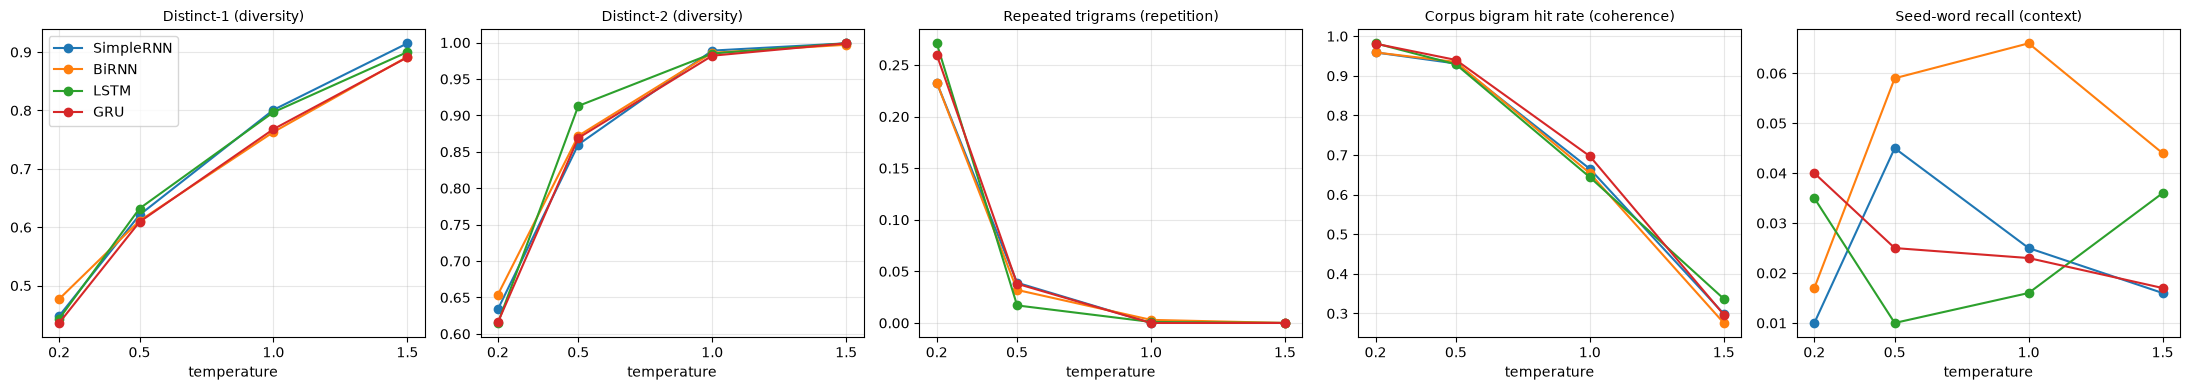

In [14]:
metric_titles = {"distinct_1": "Distinct-1 (diversity)", "distinct_2": "Distinct-2 (diversity)",
                 "rep_3": "Repeated trigrams (repetition)", "bigram_hit": "Corpus bigram hit rate (coherence)",
                 "seed_recall": "Seed-word recall (context)"}
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
summary_reset = gen_summary.reset_index()
for ax, (col, title) in zip(axes, metric_titles.items()):
    for name, g in summary_reset.groupby("model", sort=False):
        ax.plot(g.temperature, g[col], "-o", color=colors[name], label=name)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("temperature")
    ax.set_xticks(TEMPERATURES)
    ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, "temperature_effects.png"), dpi=120)
plt.show()

### Influence of temperature

The curves show the same trend for all four architectures:

| Temperature | Diversity (distinct-1 / distinct-2) | Repetition (rep-3) | Coherence (bigram hit) | Observed behaviour |
|---|---|---|---|---|
| 0.2 | low (≈0.44 / ≈0.62) | high (0.23–0.27) | very high (0.96–0.98) | grammatical but stuck in loops such as *"i have no doubt that i have…"* and *"i have heard the door of the…"* |
| 0.5 | medium (≈0.62 / ≈0.88) | low (0.02–0.04) | high (0.93–0.94) | best balance: mostly well-formed clauses, dialogue tags (*"said holmes"*) and varied content |
| 1.0 | high (≈0.78 / ≈0.99) | ≈0 | medium (0.64–0.70) | varied vocabulary and character names, but sentences lose their grammatical structure |
| 1.5 | very high (≈0.90 / ≈1.0) | 0 | low (0.28–0.34) | close to a random sequence of rare words, little coherence |

* Lowering the temperature concentrates probability mass on the most frequent continuations, which
  improves local fluency but causes repetition loops. Raising it flattens the distribution: diversity
  goes up and repetition disappears, but the share of plausible word pairs drops sharply.
* Because the sampling random stream is fixed per model and seed, the continuations at different
  temperatures often start with the same words and then drift apart, which makes the effect of the
  temperature directly visible in the samples.
* The gated models (LSTM, GRU) are more confident, so at T = 0.2 they repeat slightly more than the
  simple RNNs; at T = 0.5 and T = 1.0 the GRU has the highest corpus bigram hit rate (0.94 / 0.70).
* **Contextual consistency** is limited for every model. The seed-word recall stays below 7 %, i.e. the
  models rarely return to the topic of the seed. Consistency is mostly local: a seed ending in
  *"waiting for us at the"* is continued with a noun (*door, lamp, time, street*), and *"found him"* is
  continued with *"out"* or *"in the way"*. A 15-word window and a ~100k-word corpus are not enough to
  keep a topic over 50 generated words.

### Generated samples

The first sample for every model and temperature is printed below for seeds 1 and 2
(all seeds are saved in `results/generated_samples.txt`).

In [15]:
for s_idx in [0, 1]:
    print("=" * 100)
    print(f"SEED: {detokenize(tokenize(SEEDS[s_idx]))}")
    print("=" * 100)
    for temp in TEMPERATURES:
        print(f"\n--- temperature = {temp} ---")
        for name in models:
            txt = next(s["text"] for s in samples
                       if s["model"] == name and s["seed"] == s_idx and s["temperature"] == temp and s["sample"] == 0)
            print(f"[{name:9s}] ... {txt}")
    print()

SEED: i had called upon my friend sherlock holmes one day in the autumn of last year and found him

--- temperature = 0.2 ---
[SimpleRNN] ... . i had no doubt that i have heard it. i have heard the sound of the city, and the whole of the league, and i have no doubt that i had heard the same man. i have heard the door of the red headed men
[BiRNN    ] ... . i have a quiet. i have been given. i have been in the corner of the sort. i have no doubt that i have already to the police of the matter. i have no doubt that i have only a man who is so much
[LSTM     ] ... . i have not been able to be a little. it is a very little man, said holmes. i have not been able to be a little man. i have no doubt that you are not. i have not been able to be a little
[GRU      ] ... in the way. i have heard that i have heard that i had heard the facts of the matter, and the other is not a man who is a very serious man. i am not a very much man, and i have no doubt that i

--- temperature = 0.5 ---
[SimpleRN

### Greedy decoding (argmax) for reference

Greedy decoding is the limit `T → 0`. It shows each model's single most likely continuation and
makes repetition loops easy to see.

In [16]:
@torch.no_grad()
def generate_greedy(model, seed_text, n_words=30):
    model.eval()
    context = [stoi.get(t, UNK) for t in tokenize(seed_text)]
    for _ in range(n_words):
        logits = model(torch.tensor([context[-SEQ_LEN:]], device=device))[0]
        logits[UNK] = -float("inf")
        context.append(logits.argmax().item())
    return detokenize(itos[i] for i in context[-n_words:])

for name, model in models.items():
    print(f"[{name:9s}] ... {generate_greedy(model, SEEDS[2])}")

[SimpleRNN] ... . i have heard the same of the sort. i have heard the same of the sort. i have heard the same of the sort. i have
[BiRNN    ] ... he. i have no doubt that i have been a good of the matter. i have no doubt that i have no doubt that i have been so
[LSTM     ] ... that i have not been able to be a little man. i have not been able to be a little man. i have not been able to be
[GRU      ] ... he. i shall go to do. i shall be a very busy. i am afraid that i have been a very much. i have heard that


## 8. Discussion and conclusion

**Qualitative comparison of the generated text (T = 0.5, the most readable setting)**

* **Simple RNN** – short, locally correct phrases but frequent generic fillers (*"a very quiet"*,
  *"a very bad"*) and early loops; it forgets the sentence structure quickly.
* **Bidirectional RNN** – similar to the simple RNN, with more fragments (*"i have no. i have been the room"*)
  and the weakest perplexity; the backward pass does not help left-to-right generation.
* **LSTM** – fluent dialogue-like output (*"oh, you must have been gone. i see that the lady is not. you see,
  said holmes"*), but at low temperature it falls into the strongest repetition loop
  (*"i have not been able to be a little man"*).
* **GRU** – the most natural continuations overall, e.g. *"but how? i asked you. i do not know that i have
  the pleasure. i am compelled to do my own business."* It keeps the narrative first-person voice and the
  question/answer rhythm of the stories while avoiding long loops.

**Best model.** The **GRU** is the most effective autoregressive generator for this dataset:

1. lowest test loss and perplexity and highest top-1/top-5 accuracy,
2. faster to train than the LSTM (fewer parameters and fewer epochs to converge),
3. the highest corpus bigram hit rate at T = 0.5 and T = 1.0 with low repetition, and
4. the most coherent samples in the qualitative comparison.

The LSTM is a close second. The Bidirectional RNN is the least suitable: bidirectionality is useful when
the whole sequence is known (e.g. classification or tagging), but in autoregressive generation the
future is unknown, so it only doubles the cost and the risk of overfitting. The recommended setting is
**GRU with temperature ≈ 0.5**, which gives the best trade-off between coherence and diversity.

**Limitations and possible improvements.** The corpus is small, so all models overfit early; a larger
corpus (e.g. all Sherlock Holmes books), longer context windows, stronger regularisation, pretrained word
embeddings, top-k / nucleus sampling, or a Transformer decoder would further improve coherence and
long-range consistency.